cercle détecté : centre=(1740, 358), taille=314
cercle détecté : centre=(2254, 1711), taille=260
cercle détecté : centre=(1270, 1006), taille=302
cercle détecté : centre=(2820, 1169), taille=296
cercle détecté : centre=(2734, 372), taille=338
cercle détecté : centre=(2071, 1049), taille=230
cercle détecté : centre=(1586, 1745), taille=326
cercle détecté : centre=(713, 1385), taille=234
cercle détecté : centre=(953, 338), taille=226
9 cercles détectés


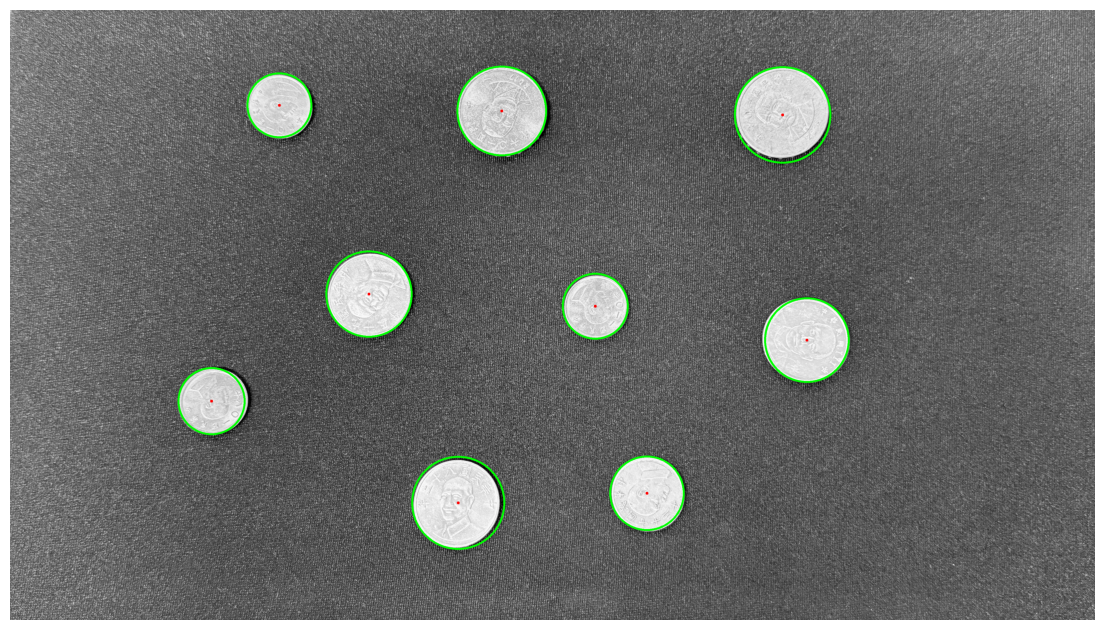

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import cv2
#import scikit-image as skimage

chemin = './data/image2.jpg'
piece = cv2.imread(chemin, cv2.IMREAD_GRAYSCALE) # on force l'image a rester en niveau de gris (car c'est plus simple pour detecter les cercles)
#piece = piece[220:1900, 750:2800] # on recadre jsp si c'est vrm utile
echelle = 0.25
piece_reduite = cv2.resize(piece, None, fx=echelle, fy=echelle, interpolation=cv2.INTER_AREA) # pour reduire la quelité pour que ça aille plus vite
piece_floue = cv2.medianBlur(piece_reduite, 5) # pour ne pas etre perturbé par certain détail (c'est juste pour la detection des cercles)
image_resultat = cv2.cvtColor(piece, cv2.COLOR_GRAY2RGB) # permet a la fin de pouvoir rajouter des couleurs sur l'image (car plus tot j'ai forcer l'image a rester en niveau de gris)

cercles = cv2.HoughCircles(
    piece_floue, # l'image sur la quel on cherche les cercles
    cv2.HOUGH_GRADIENT, # la methode
    dp=1.2, # a quel point ça dois etre un cercle parfait (1 c'est parfait, 1.2 ça peut être légeremnt oval)
    minDist=65, # la distance minimale entre 2 cercle, pour eviter de detecter 2 fois la mme piece
    param1=100, # plus c'est haut plus le contours doit etre net pour etre detecte
    param2=30, # le taux de fiabilité (plus c'est haut plus il a tendance a detecter des cercle)
    minRadius=25, # les limite de tailles des rayons des cercle
    maxRadius=60,
)

if piece is None:
    raise FileNotFoundError(f'Image introuvable : {chemin}')

if cercles is None:
    print('Aucun cercle détecté. Essaie de diminuer param2 ou ajuste minRadius/maxRadius.')
else:
    cercles = np.round(cercles[0] / echelle).astype(int)
    for x, y, rayon in cercles:
        cv2.circle(image_resultat, (x, y), rayon, (0, 255, 0), 5)
        cv2.circle(image_resultat, (x, y), 5, (255, 0, 0), -1)
        print(f'cercle détecté : centre=({x}, {y}), taille={rayon*2}')
    print(f'{len(cercles)} cercles détectés')

plt.figure(figsize=(14, 8))
plt.imshow(image_resultat)
plt.axis('off')
plt.show()

cercle détecté : centre=(1577, 1362), taille=372
cercle détecté : centre=(2352, 1807), taille=428
cercle détecté : centre=(1278, 902), taille=312
cercle détecté : centre=(2738, 1322), taille=538
cercle détecté : centre=(1737, 758), taille=212
5 cercles détectés


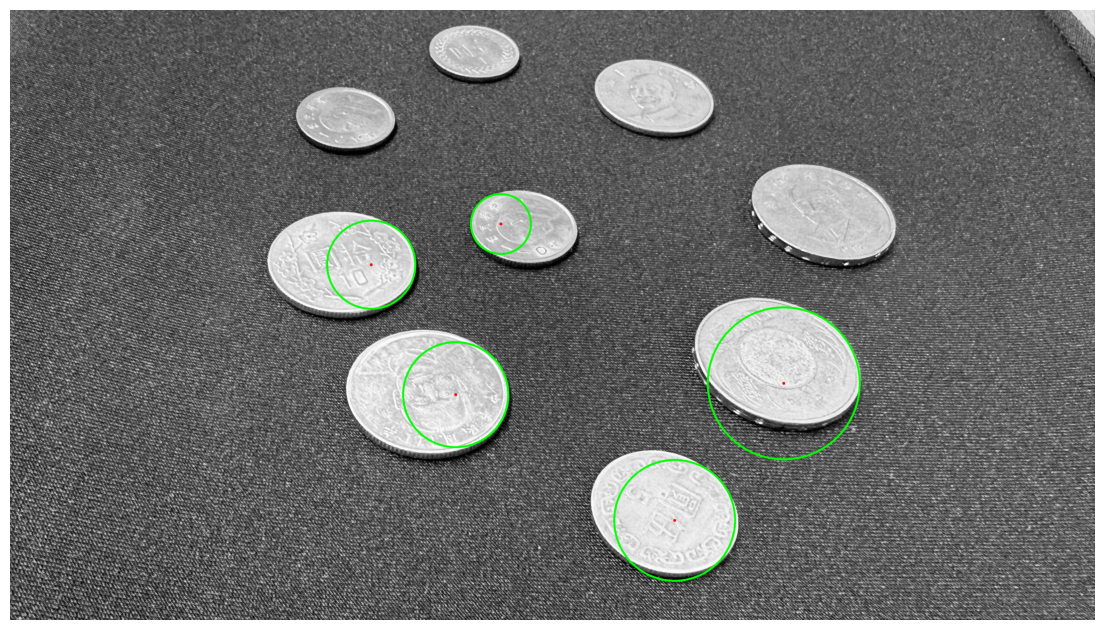

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import cv2

chemin = './data/image4.jpg'
piece = cv2.imread(chemin, cv2.IMREAD_GRAYSCALE)
echelle = 0.30
piece_reduite = cv2.resize(piece, None, fx=echelle, fy=echelle, interpolation=cv2.INTER_AREA)
piece_floue = cv2.medianBlur(piece_reduite, 5)
image_resultat = cv2.cvtColor(piece, cv2.COLOR_GRAY2RGB)

cercles = cv2.HoughCircles(
    piece_floue,
    cv2.HOUGH_GRADIENT,
    dp=1.5,
    minDist=65,
    param1=135,
    param2=58,
    minRadius=29,
    maxRadius=85,
)

if piece is None:
    raise FileNotFoundError(f'Image introuvable : {chemin}')

if cercles is None:
    print('Aucun cercle détecté. Essaie de diminuer param2 ou ajuste minRadius/maxRadius.')
else:
    cercles = np.round(cercles[0] / echelle).astype(int)
    for x, y, rayon in cercles:
        cv2.circle(image_resultat, (x, y), rayon, (0, 255, 0), 5)
        cv2.circle(image_resultat, (x, y), 5, (255, 0, 0), -1)
        print(f'cercle détecté : centre=({x}, {y}), taille={rayon*2}')
    print(f'{len(cercles)} cercles détectés')

plt.figure(figsize=(14, 8))
plt.imshow(image_resultat)
plt.axis('off')
plt.show()

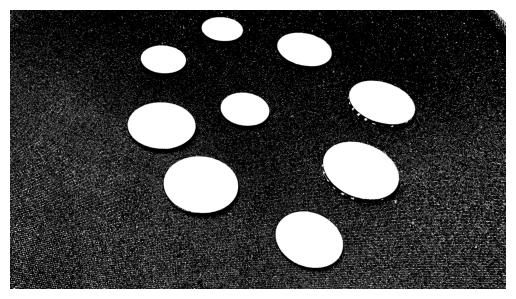

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import cv2

image = './data/image4.jpg'

img = cv2.imread(image, cv2.IMREAD_GRAYSCALE)

seuil, img_binaire = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

plt.imshow(img_binaire, cmap='gray', vmin=0, vmax=255)
plt.axis('off')
plt.show()